# 1) Mount drive

In [36]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 2) Import libraries

In [37]:
pip install deslib

In [38]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import BaggingClassifier

#importing DCS techniques from DESlib
from deslib.dcs.ola import OLA
from deslib.dcs.a_priori import APriori
from deslib.dcs.mcb import MCB

#import DES techniques from DESlib
from deslib.des.des_p import DESP
from deslib.des.knora_u import KNORAU
from deslib.des.knora_e import KNORAE
from deslib.des.meta_des import METADES

from sklearn.metrics import confusion_matrix,classification_report


# 3) read dataset

In [39]:
df= pd.read_csv('/content/drive/MyDrive/ML/ML/تمرین سوم/Data/data.csv')
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [40]:
df.shape

(569, 33)

# 4) preprocess the dataset

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [42]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [43]:
df.columns

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')

In [44]:
df["diagnosis"].value_counts()

,count
diagnosis,
B,357
M,212


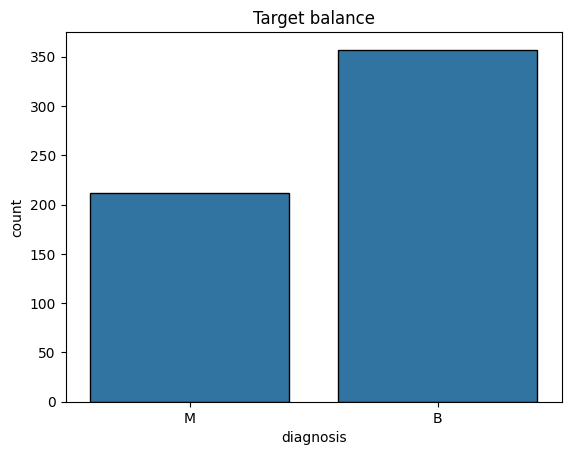

In [45]:
sns.countplot(data = df, x = "diagnosis",
              edgecolor = 'k')
plt.title("Target balance");

In [46]:
df.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


In [47]:
# Duplicated observations
df.duplicated().sum()

np.int64(0)

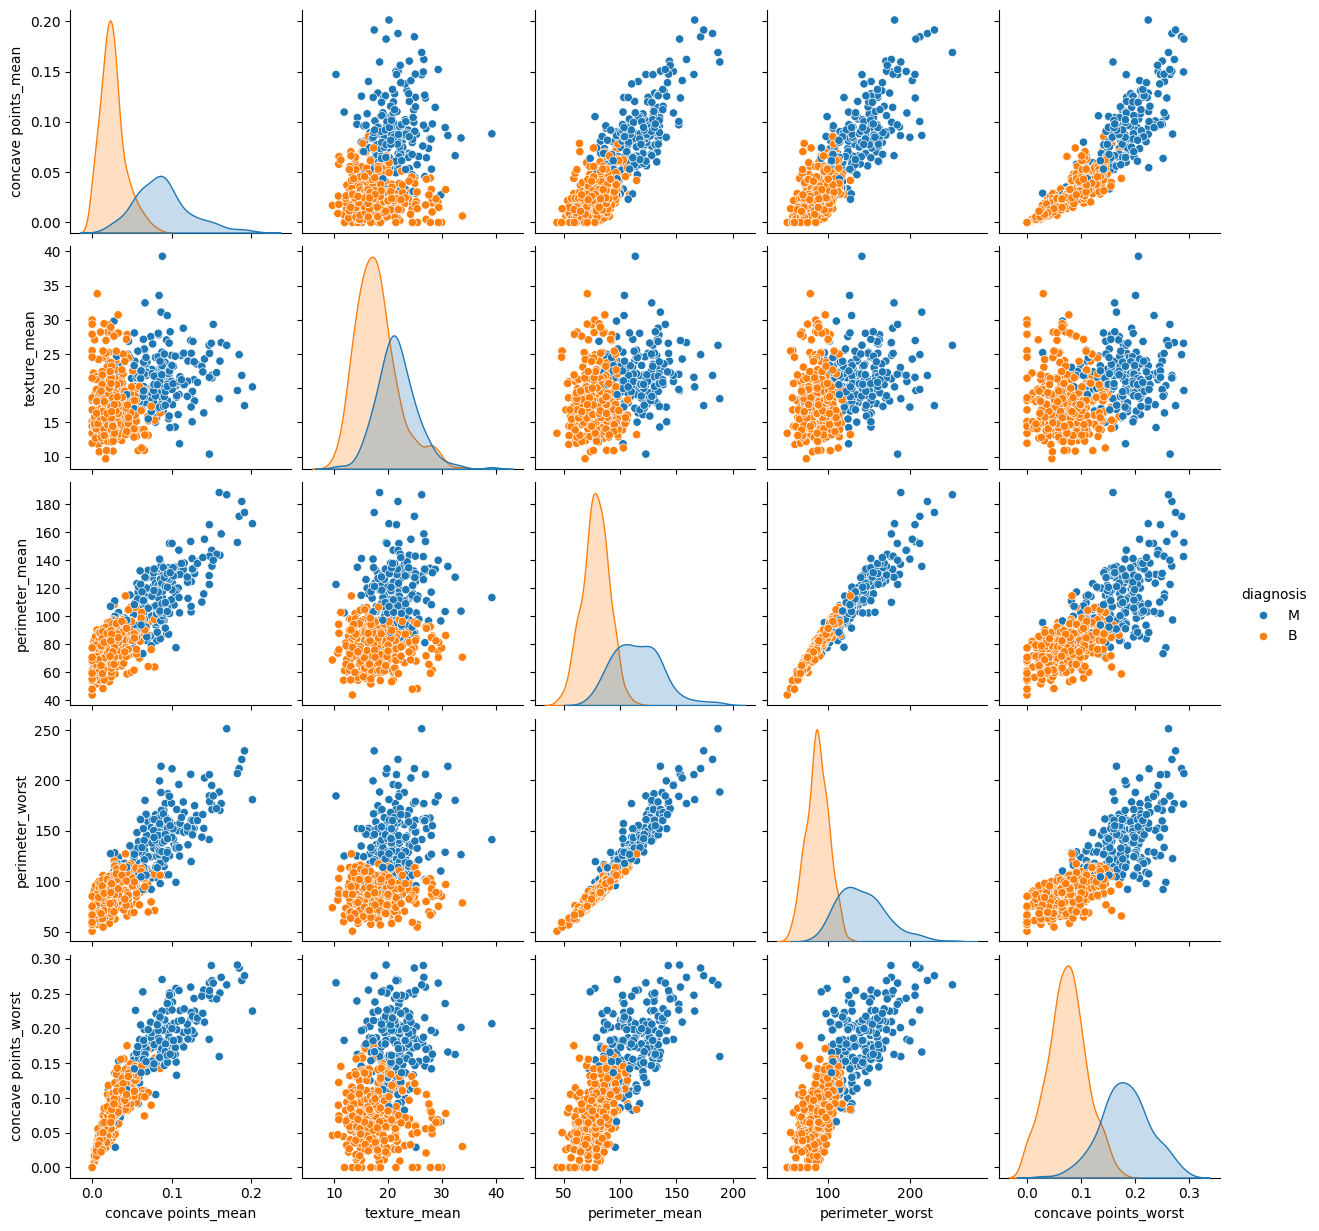

In [48]:
sns.pairplot(df, hue="diagnosis", vars=["concave points_mean", "texture_mean", "perimeter_mean", "perimeter_worst", "concave points_worst"])
plt.show()

In [49]:
df = df.drop(['id','Unnamed: 32'], axis=1)

In [50]:
from sklearn import preprocessing
from sklearn.preprocessing import LabelEncoder

In [51]:
encoder = LabelEncoder()
df['diagnosis']=encoder.fit_transform(df['diagnosis'])

In [52]:
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [53]:
data_mean = df[['diagnosis','radius_mean','texture_mean','perimeter_mean','area_mean','smoothness_mean', 'compactness_mean', 'concavity_mean','concave points_mean', 'symmetry_mean', 'fractal_dimension_mean']]

We will just see how these features coorelate with the diagnosis using heatmap:

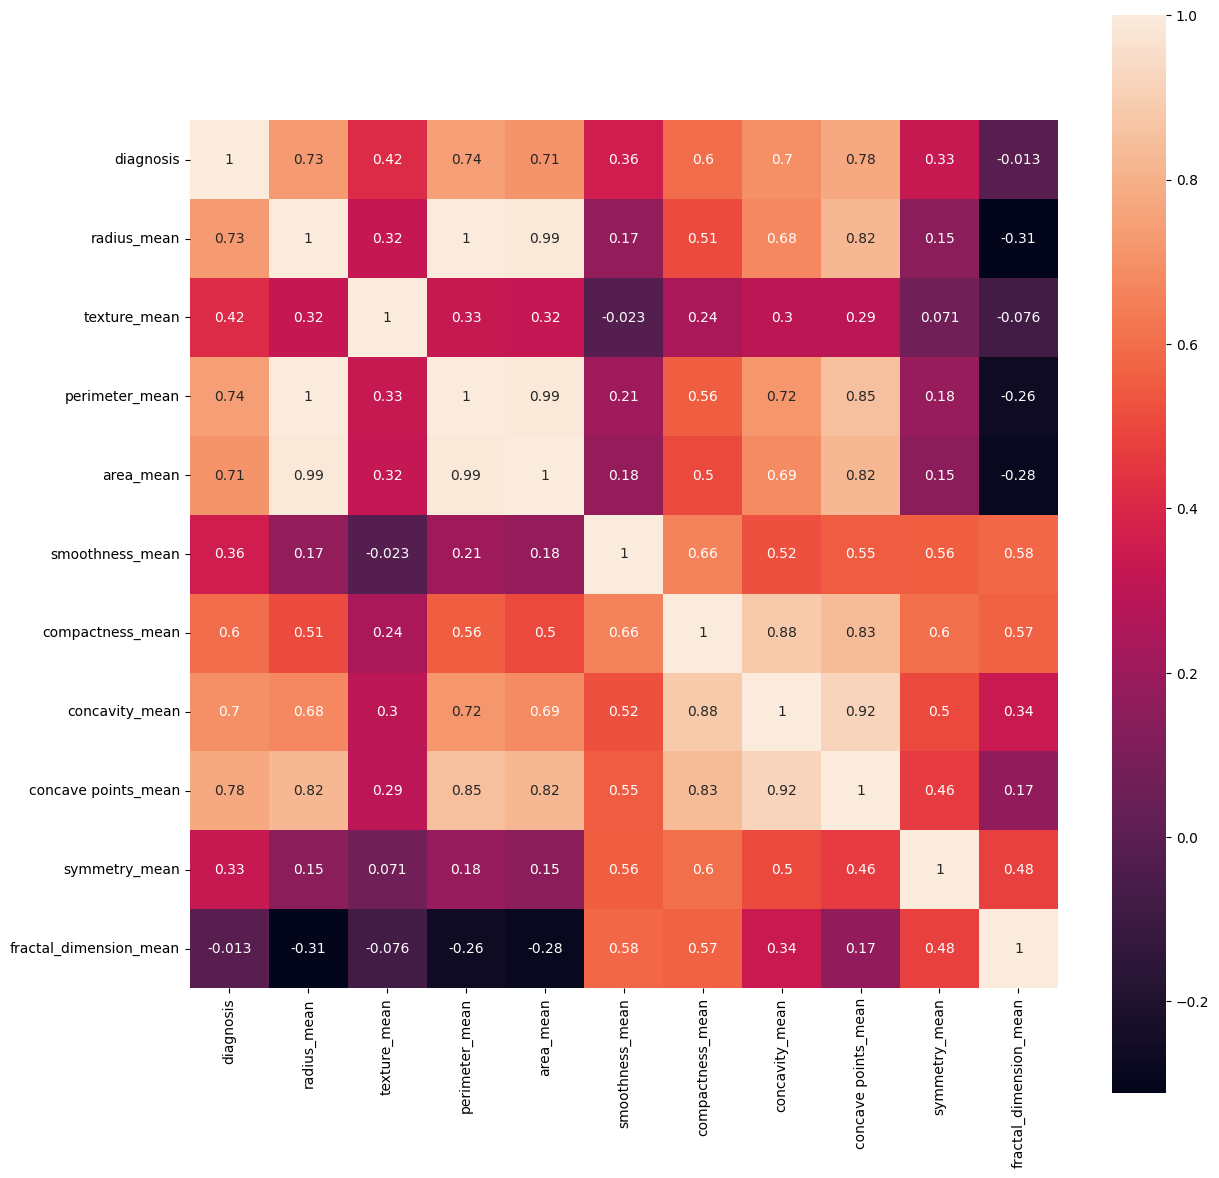

In [54]:
plt.figure(figsize=(14,14))
foo = sns.heatmap(data_mean.corr(), vmax=1, square=True, annot=True)

# 5) fit meta-DES model

Preparing the dataset:

In [55]:
X = df.drop(['diagnosis'], axis=1)
y = df['diagnosis']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, stratify=y, random_state=42)

# Scale the variables to have 0 mean and unit variance
scalar = StandardScaler()
X_train = scalar.fit_transform(X_train)
X_test = scalar.transform(X_test)

X_train, X_dsel, y_train, y_dsel = train_test_split(X_train, y_train, test_size=0.5, stratify=y_train, random_state=42)

Training a pool of classifiers:

In [56]:
model = CalibratedClassifierCV(Perceptron(max_iter=10))

# Train a pool of 10 classifiers
pool_classifiers = BaggingClassifier(model, n_estimators=10)
pool_classifiers.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic

BaggingClassifier(estimator=CalibratedClassifierCV(estimator=Perceptron(max_iter=10)))

Building the DS models

In [57]:
# DES techniques
meta = METADES(pool_classifiers=pool_classifiers)

Fitting the DS techniques:

In [58]:
meta.fit(X_dsel, y_dsel)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


METADES(pool_classifiers=BaggingClassifier(estimator=CalibratedClassifierCV(estimator=Perceptron(max_iter=10))))

Estimating classification accuracy:

In [59]:
print('Classification accuracy META-DES: ', meta.score(X_test, y_test))

Classification accuracy META-DES:  0.9361702127659575


In [60]:
y_pred = meta.predict(X_test)
y_pred_proba = meta.predict_proba(X_test)

print('y_pred: ', y_pred[:10])
print('y_pred proba: ', y_pred_proba[:10])

y_pred:  [0 0 0 0 0 0 0 1 1 0]
y_pred proba:  [[0.63603767 0.36396233]
 [0.7392517  0.2607483 ]
 [0.9707661  0.0292339 ]
 [0.97402407 0.02597593]
 [0.93878405 0.06121595]
 [0.68710501 0.31289499]
 [0.96190932 0.03809068]
 [0.1103572  0.8896428 ]
 [0.07237857 0.92762143]
 [0.5        0.5       ]]


In [61]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[118   0]
 [ 12  58]]


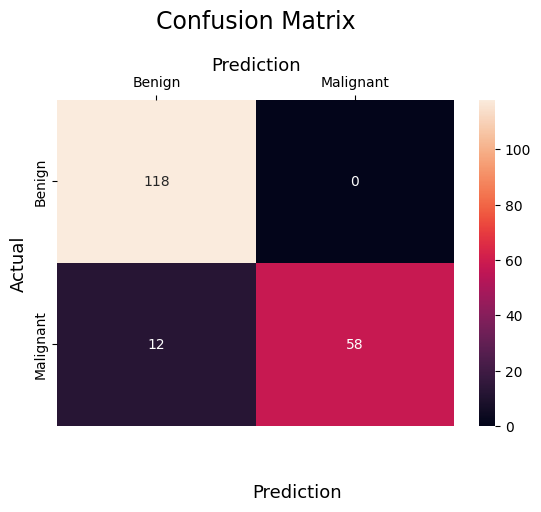

In [62]:
sns.heatmap(cm,
            annot=True,
            fmt='g',
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'])
plt.ylabel('Actual', fontsize=13)
plt.title('Confusion Matrix', fontsize=17, pad=20)
plt.gca().xaxis.set_label_position('top')
plt.xlabel('Prediction', fontsize=13)
plt.gca().xaxis.tick_top()

plt.gca().figure.subplots_adjust(bottom=0.2)
plt.gca().figure.text(0.5, 0.05, 'Prediction', ha='center', fontsize=13)
plt.show()

In [63]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      1.00      0.95       118
           1       1.00      0.83      0.91        70

    accuracy                           0.94       188
   macro avg       0.95      0.91      0.93       188
weighted avg       0.94      0.94      0.93       188



# 6) K Fold Cross Validation

In [64]:

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import Perceptron
from sklearn.ensemble import BaggingClassifier
from deslib.des.meta_des import METADES
from sklearn.metrics import accuracy_score
from statistics import mean, stdev
import numpy as np

X = df.drop(['diagnosis'], axis=1)
y = df['diagnosis']

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = []

for train_index, test_index in skf.split(X, y):

    # Split into Train and Test
    X_train_fold = X.iloc[train_index]
    X_test_fold = X.iloc[test_index]
    y_train_fold = y.iloc[train_index]
    y_test_fold = y.iloc[test_index]

    # Split Train into Train and DSEL
    X_train, X_dsel, y_train, y_dsel = train_test_split(
        X_train_fold,
        y_train_fold,
        test_size=0.5,
        stratify=y_train_fold,
        random_state=42
    )

    # Scale data without leakage
    scaler = MinMaxScaler()
    X_train = scaler.fit_transform(X_train)
    X_dsel = scaler.transform(X_dsel)
    X_test_fold = scaler.transform(X_test_fold)

    # Train the pool of classifiers
    model = CalibratedClassifierCV(Perceptron(max_iter=10))
    pool_classifiers = BaggingClassifier(model, n_estimators=10)
    pool_classifiers.fit(X_train, y_train)

    # Train META-DES
    meta = METADES(pool_classifiers=pool_classifiers)
    meta.fit(X_dsel, y_dsel)

    # Evaluate
    y_pred = meta.predict(X_test_fold)
    scores.append(accuracy_score(y_test_fold, y_pred))

print("Accuracy scores for each fold:", scores)
print("Mean Accuracy:", mean(scores))
print("Standard Deviation:", stdev(scores))
print("Maximum Accuracy:", max(scores))
print("Minimum Accuracy:", min(scores))


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic

Accuracy scores for each fold: [0.9824561403508771, 0.9473684210526315, 0.9385964912280702, 0.9824561403508771, 0.9734513274336283]
Mean Accuracy: 0.9648657040832168
Standard Deviation: 0.020547422478073604
Maximum Accuracy: 0.9824561403508771
Minimum Accuracy: 0.9385964912280702


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic

Confusion Matrix:
[[357   0]
 [ 19 193]]


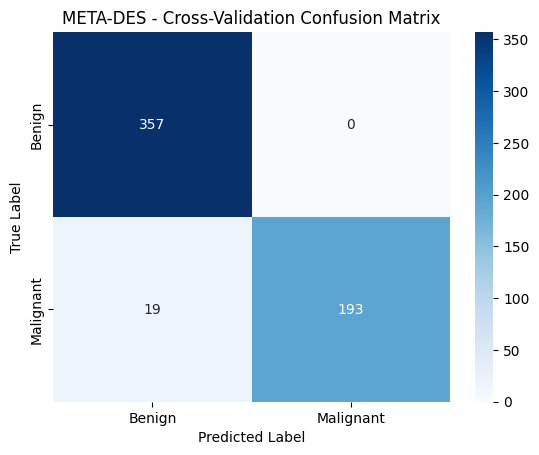


Classification Report:
              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97       357
   Malignant       1.00      0.91      0.95       212

    accuracy                           0.97       569
   macro avg       0.97      0.96      0.96       569
weighted avg       0.97      0.97      0.97       569



In [65]:
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score
)
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

all_y_test = []
all_y_pred = []

for train_index, test_index in skf.split(X, y):

    X_train_fold, X_test_fold = X.iloc[train_index], X.iloc[test_index]
    y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]

    X_train_fold, X_dsel_fold, y_train_fold, y_dsel_fold = train_test_split(
        X_train_fold, y_train_fold,
        test_size=0.5,
        stratify=y_train_fold,
        random_state=42
    )

    scaler = MinMaxScaler()
    X_train_fold = scaler.fit_transform(X_train_fold)
    X_dsel_fold = scaler.transform(X_dsel_fold)
    X_test_fold = scaler.transform(X_test_fold)

    model = CalibratedClassifierCV(Perceptron(max_iter=10))
    pool_classifiers = BaggingClassifier(model, n_estimators=10)
    pool_classifiers.fit(X_train_fold, y_train_fold)

    meta = METADES(pool_classifiers=pool_classifiers)
    meta.fit(X_dsel_fold, y_dsel_fold)

    y_pred = meta.predict(X_test_fold)

    all_y_test.extend(y_test_fold)
    all_y_pred.extend(y_pred)

cm = confusion_matrix(all_y_test, all_y_pred)

print("Confusion Matrix:")
print(cm)

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('META-DES - Cross-Validation Confusion Matrix')
plt.show()

print("\nClassification Report:")
print(classification_report(
    all_y_test, all_y_pred,
    target_names=['Benign', 'Malignant']
))

# 7) optimize parameters

In [66]:
import pandas as pd
import numpy as np

from sklearn.model_selection import ParameterGrid, StratifiedKFold, train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import Perceptron
from sklearn.ensemble import BaggingClassifier

from deslib.des.meta_des import METADES

# Prepare data
X = df.drop(['diagnosis'], axis=1)
y = df['diagnosis']

# Parameter Grid (24 combinations)
param_grid = {
    'k': [5, 7],
    'Kp': [3, 5],
    'Hc': [0.5, 1.0],
    'selection_threshold': [0.6, 0.8],
    'mode': ['selection', 'hybrid']
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for params in ParameterGrid(param_grid):
    scores = []

    for train_index, test_index in skf.split(X, y):

        X_train_fold = X.iloc[train_index]
        X_test_fold = X.iloc[test_index]
        y_train_fold = y.iloc[train_index]
        y_test_fold = y.iloc[test_index]

        X_train, X_dsel, y_train, y_dsel = train_test_split(
            X_train_fold, y_train_fold,
            test_size=0.5,
            stratify=y_train_fold,
            random_state=42
        )

        scaler = MinMaxScaler()
        X_train = scaler.fit_transform(X_train)
        X_dsel = scaler.transform(X_dsel)
        X_test_fold = scaler.transform(X_test_fold)

        model = CalibratedClassifierCV(
            Perceptron(max_iter=1000, random_state=42)
        )

        pool = BaggingClassifier(
            estimator=model,
            n_estimators=10,
            random_state=42
        )
        pool.fit(X_train, y_train)

        meta = METADES(pool_classifiers=pool, **params)
        meta.fit(X_dsel, y_dsel)

        y_pred = meta.predict(X_test_fold)
        scores.append(np.mean(y_pred == y_test_fold))

    results.append({
        **params,
        'Mean Accuracy': np.mean(scores)
    })

# Display results
results_df = pd.DataFrame(results).sort_values(
    'Mean Accuracy', ascending=False
).reset_index(drop=True)

print("Top Results:")
print(results_df.head(10))

print("\nBest Parameters:")
print(results_df.iloc[0][
    ['k', 'Kp', 'Hc', 'selection_threshold', 'mode']
])

print("\nBest Accuracy:")
print(results_df.iloc[0]['Mean Accuracy'])


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator.

Top Results:
    Hc  Kp  k       mode  selection_threshold  Mean Accuracy
0  1.0   3  7     hybrid                  0.8       0.961372
1  0.5   5  5     hybrid                  0.8       0.961357
2  1.0   5  5  selection                  0.6       0.961357
3  1.0   5  5     hybrid                  0.8       0.961357
4  1.0   5  5  selection                  0.8       0.959603
5  0.5   5  5  selection                  0.8       0.959603
6  1.0   5  7  selection                  0.8       0.959603
7  1.0   5  7  selection                  0.6       0.959603
8  1.0   3  5     hybrid                  0.6       0.959603
9  1.0   3  7     hybrid                  0.6       0.959603

Best Parameters:
k                           7
Kp                          3
Hc                        1.0
selection_threshold       0.8
mode                   hybrid
Name: 0, dtype: object

Best Accuracy:
0.9613724576929048


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


In [67]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Prepare data
X = df.drop(['diagnosis'], axis=1)
y = df['diagnosis']

# Split Train and Test
X_train_fold, X_test, y_train_fold, y_test = train_test_split(
    X, y, test_size=0.33, stratify=y, random_state=42
)

# Split Train into Train and DSEL
X_train, X_dsel, y_train, y_dsel = train_test_split(
    X_train_fold, y_train_fold,
    test_size=0.5, stratify=y_train_fold, random_state=42
)

# Scaling
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_dsel = scaler.transform(X_dsel)
X_test = scaler.transform(X_test)

# Train pool
model = CalibratedClassifierCV(
    Perceptron(max_iter=1000, random_state=42)
)
pool_classifiers = BaggingClassifier(
    estimator=model, n_estimators=10, random_state=42
)
pool_classifiers.fit(X_train, y_train)

# Optimized META-DES
best_meta = METADES(
    pool_classifiers=pool_classifiers,
    k=7, Kp=3, Hc=1.0,
    selection_threshold=0.8,
    mode='hybrid'
)
best_meta.fit(X_dsel, y_dsel)

# Prediction and evaluation
y_pred_best = best_meta.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_best))
print(classification_report(
    y_test, y_pred_best,
    target_names=['Benign', 'Malignant']
))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))


Accuracy: 0.9414893617021277
              precision    recall  f1-score   support

      Benign       0.91      1.00      0.96       118
   Malignant       1.00      0.84      0.91        70

    accuracy                           0.94       188
   macro avg       0.96      0.92      0.94       188
weighted avg       0.95      0.94      0.94       188

Confusion Matrix:
[[118   0]
 [ 11  59]]


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


## Results and Model Comparison

### Model Performance

| Evaluation Method | Accuracy | Precision (Malignant) | Recall (Malignant) | F1-score (Malignant) |
|---|---:|---:|---:|---:|
| Initial META-DES (Holdout) | 93.62% | 100% | 83% | 91% |
| META-DES (5-Fold Cross-Validation) | 96.49% ± 2.05% | — | — | — |
| Optimized META-DES (5-Fold CV) | 96.14% | — | — | — |
| Optimized META-DES (Holdout) | 94.15% | 100% | 84% | 91% |

### Best Hyperparameters

| Parameter | Best Value |
|---|---:|
| k | 7 |
| Kp | 3 |
| Hc | 1.0 |
| selection_threshold | 0.8 |
| mode | hybrid |

### Conclusion

The META-DES model achieved an accuracy of 93.62% on the initial holdout test set. It obtained 100% precision and approximately 83% recall for malignant cases, indicating that some malignant samples were incorrectly classified as benign.

The initial 5-fold cross-validation achieved a mean accuracy of 96.49% ± 2.05%. After hyperparameter optimization, the best cross-validation accuracy was 96.14%, using the parameter configuration listed above. The optimized model achieved 94.15% accuracy on the holdout evaluation.

Overall, META-DES demonstrated promising classification performance on the Breast Cancer Wisconsin Diagnostic dataset. However, improving the detection of malignant cases remains important, since missing malignant samples can have serious consequences.

**Evaluation Note:** The hyperparameter search was performed using the complete dataset, including samples later used in the holdout evaluation. Therefore, the optimized holdout result should not be considered a fully independent estimate of generalization performance.